# Thực nghiệm đọc đồng hồ nước - Phúc

Đã chạy E1/E2 trên dữ liệu thật ngày 15/11/2026. E3, E4 đọc từ `experiments/quang/results/`. Notebook đọc CSV đã lưu để tái lập hình và bảng; lệnh thực nghiệm trong experiments/phuc/README.md. Chạy lại notebook không chọn lại tham số và không chạy lại eval.

In [1]:
from pathlib import Path
import csv, json
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, Image
ROOT = Path.cwd() if (Path.cwd() / 'src').exists() else Path.cwd().parent
RESULTS = ROOT / 'experiments/phuc/results'
QUANG = ROOT / 'experiments/quang/results'
def table(name, folder=RESULTS):
    path = folder / name
    if not path.exists():
        display(Markdown(f'**Chưa có `{name}` - chưa thể kết luận.**'))
        return []
    with path.open(encoding='utf-8') as f:
        rows = list(csv.DictReader(f))
    display(rows)
    return rows


## E1 - Chứng cứ thách thức

So sánh đúng cùng vị trí chữ số qua ba tầng. Quan sát bốn số đầu làm đối chứng. Độ sáng, tương phản và Laplacian variance chỉ là proxy của nhiễu; không thay thế kiểm soát loại đồng hồ. Quan hệ thống kê không đủ kết luận độ lăn là nguyên nhân duy nhất.

In [2]:
summary = table('summary.csv')
controls = table('e1_control_summary.csv')

[{'method': 'baseline',
  'tier': 'all',
  'n': '2000',
  'd1': '0.964',
  'd2': '0.908',
  'd3': '0.871',
  'd4': '0.8535',
  'd5': '0.4825',
  'first4': '0.899125',
  'full': '0.3715',
  'last_errors': '1035',
  'adjacent_errors': '252',
  'adjacent_fraction': '0.24347826086956523'},
 {'method': 'baseline',
  'tier': 'light',
  'n': '437',
  'd1': '0.9633867276887872',
  'd2': '0.9016018306636155',
  'd3': '0.8489702517162472',
  'd4': '0.8306636155606407',
  'd5': '0.6407322654462243',
  'first4': '0.8861556064073227',
  'full': '0.5148741418764302',
  'last_errors': '157',
  'adjacent_errors': '45',
  'adjacent_fraction': '0.28662420382165604'},
 {'method': 'baseline',
  'tier': 'medium',
  'n': '1156',
  'd1': '0.9662629757785467',
  'd2': '0.907439446366782',
  'd3': '0.8737024221453287',
  'd4': '0.856401384083045',
  'd5': '0.5198961937716263',
  'first4': '0.9009515570934256',
  'full': '0.3944636678200692',
  'last_errors': '555',
  'adjacent_errors': '138',
  'adjacent_fract

[{'tier': 'light',
  'n': '437',
  'brightness_mean': '168.9671075514874',
  'brightness_std': '22.270034657032898',
  'contrast_mean': '38.95175889113058',
  'contrast_std': '9.586902490515381',
  'sharpness_mean': '605.8265298263253',
  'sharpness_std': '526.382962479576',
  'half_word_mean': '0.06178489702517163',
  'half_word_std': '0.2407644565228858'},
 {'tier': 'medium',
  'n': '1156',
  'brightness_mean': '171.32627861880047',
  'brightness_std': '21.986314078773844',
  'contrast_mean': '38.31373612933549',
  'contrast_std': '9.65059354654505',
  'sharpness_mean': '635.8902980668073',
  'sharpness_std': '492.9157344674137',
  'half_word_mean': '0.07698961937716263',
  'half_word_std': '0.2665749761048892'},
 {'tier': 'heavy',
  'n': '407',
  'brightness_mean': '173.00330876330875',
  'brightness_std': '22.42252278283014',
  'contrast_mean': '39.97811424271837',
  'contrast_std': '8.847187300356417',
  'sharpness_mean': '653.4634035082754',
  'sharpness_std': '470.7555590736807'

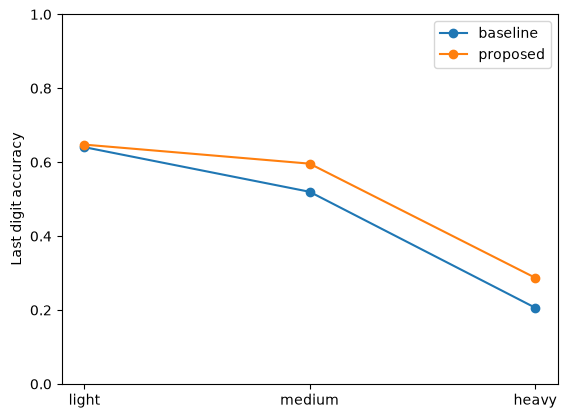

In [3]:
if summary:
    tiers = ['light', 'medium', 'heavy']
    for method in sorted({r['method'] for r in summary}):
        group = {r['tier']: r for r in summary if r['method'] == method}
        plt.plot(tiers, [float(group[t]['d5']) for t in tiers], marker='o', label=method)
    plt.ylim(0,1); plt.ylabel('Last digit accuracy'); plt.legend(); plt.show()
else:
    print('Chưa có kết quả E1 để nhận xét mức suy giảm.')

## E2 - Khảo sát tham số trên dev_val

Pitch điều chỉnh khoảng cách giữa hai chữ số; bán kính dịch ngang bù lệch ô; ngưỡng quyết định thời điểm chuyển nhãn. Mỗi tham số có ít nhất ba giá trị. Bảng kèm accuracy theo tầng; ảnh trung gian dùng mẫu dev_val, không chọn ảnh eval để điều chỉnh phương pháp.

[{'pitch': '54',
  'max_shift': '2',
  'threshold': '0.4',
  'n': '2290',
  'last_accuracy': '0.3943231441048035',
  'light': '0.46898263027295284',
  'medium': '0.4931756141947225',
  'heavy': '0.2182741116751269'},
 {'pitch': '54',
  'max_shift': '2',
  'threshold': '0.5',
  'n': '2290',
  'last_accuracy': '0.3930131004366812',
  'light': '0.4739454094292804',
  'medium': '0.49226569608735216',
  'heavy': '0.2131979695431472'},
 {'pitch': '54',
  'max_shift': '2',
  'threshold': '0.6',
  'n': '2290',
  'last_accuracy': '0.3890829694323144',
  'light': '0.46153846153846156',
  'medium': '0.49044585987261147',
  'heavy': '0.21065989847715735'},
 {'pitch': '54',
  'max_shift': '6',
  'threshold': '0.4',
  'n': '2290',
  'last_accuracy': '0.4497816593886463',
  'light': '0.575682382133995',
  'medium': '0.543221110100091',
  'heavy': '0.2550761421319797'},
 {'pitch': '54',
  'max_shift': '6',
  'threshold': '0.5',
  'n': '2290',
  'last_accuracy': '0.448471615720524',
  'light': '0.57568

{'config': {'pitch': 58,
  'threshold': 0.4,
  'max_shift': 6,
  'enabled': True,
  'continuous': True},
 'selection_split': 'dev_val',
 'criterion': 'last_accuracy',
 'split_sha256': {'dev_fit.csv': 'd2ffc59f33dbcbd11bdfbe2ac85ad48565073f9c82fa4afedf78047d93e388c3',
  'dev_val.csv': '82b7d370f472886b2a162f259ccd1bba82ff7377e4bae8e08437c0471fbc4ed6',
  'eval.csv': 'a658452ac6da835a1922c2cfefd6db5151b03afa783c07569e9e97c9f90a7cbb'}}

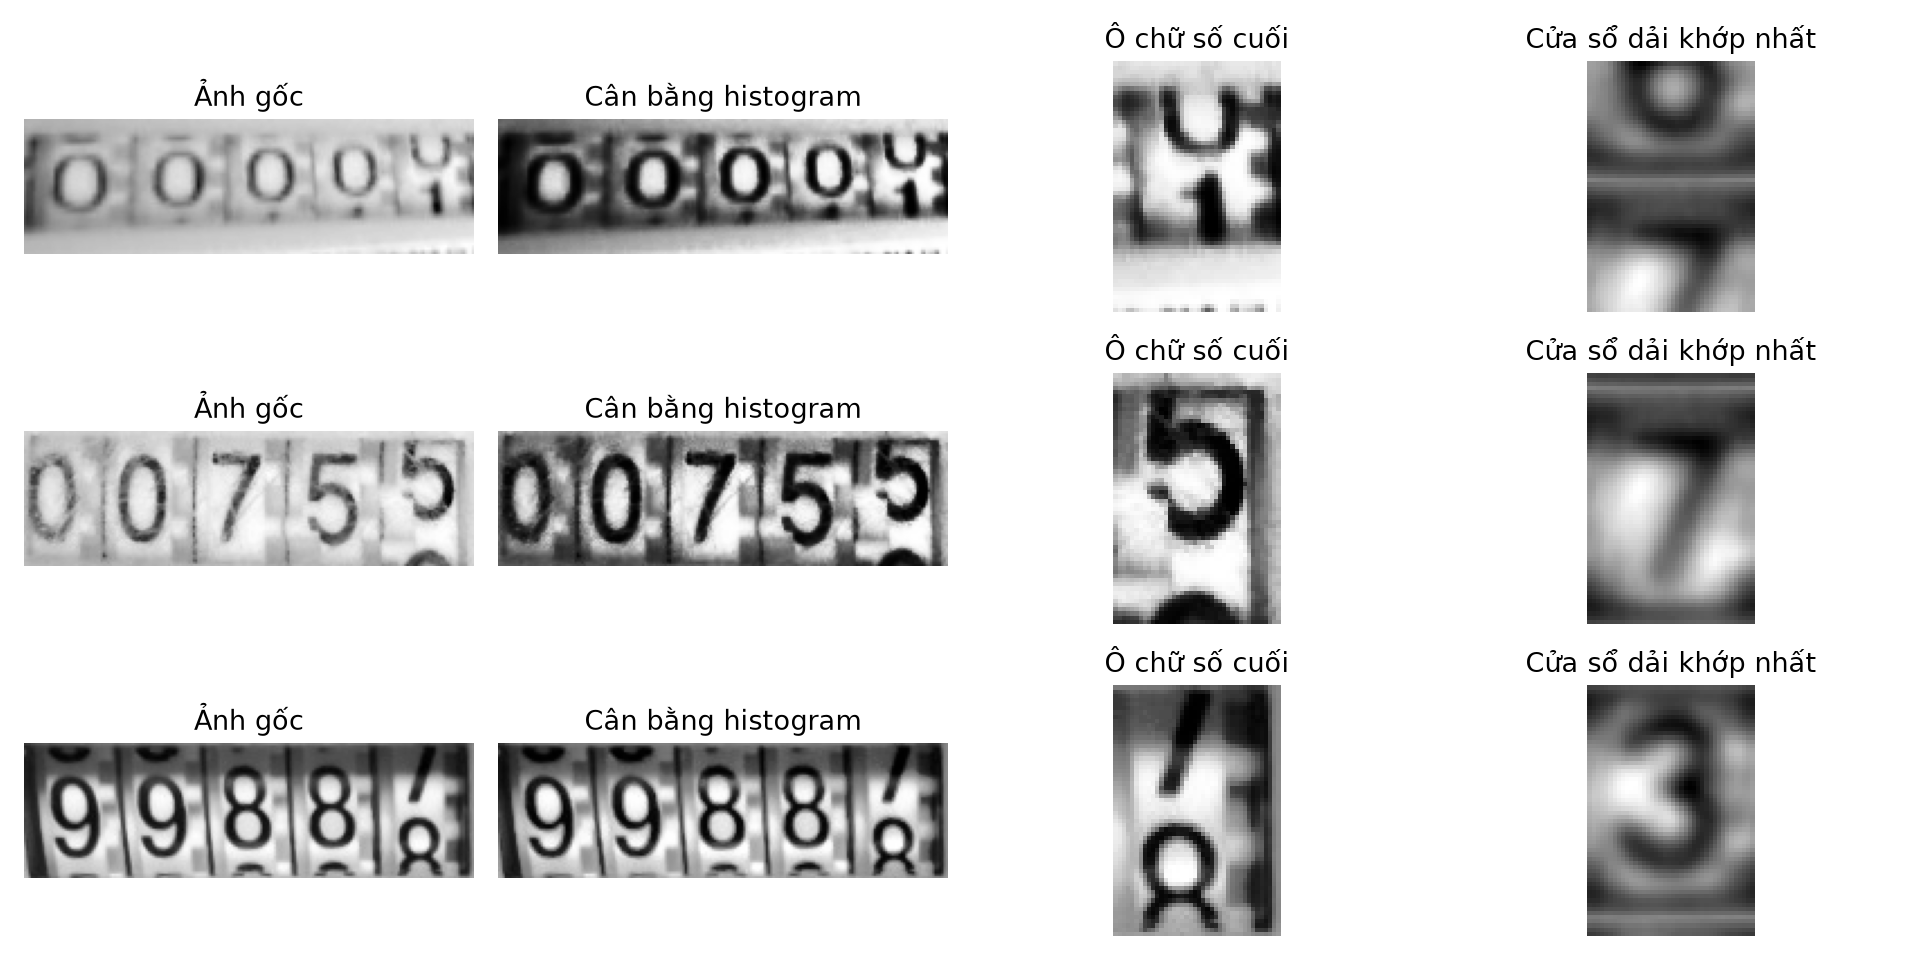

In [4]:
grid = table('e2_grid.csv')
if (RESULTS/'selected.json').exists():
    display(json.loads((RESULTS/'selected.json').read_text()))
if (RESULTS/'e2_intermediates.png').exists():
    display(Image(filename=str(RESULTS/'e2_intermediates.png')))

Cấu hình tốt nhất trên dev_val: pitch=58, shift=6, threshold=0.4; accuracy=0.454. Chưa được suy ra cải thiện trên eval từ bảng này.

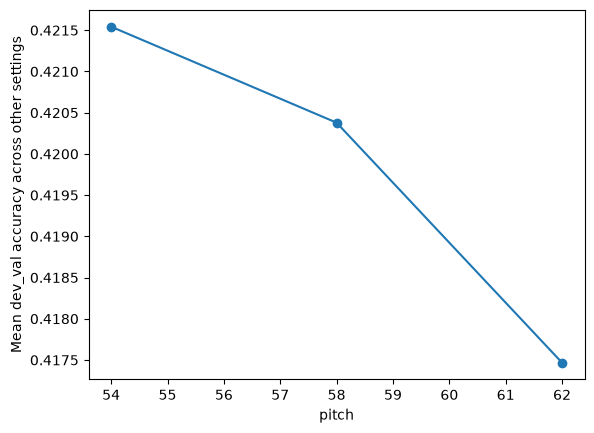

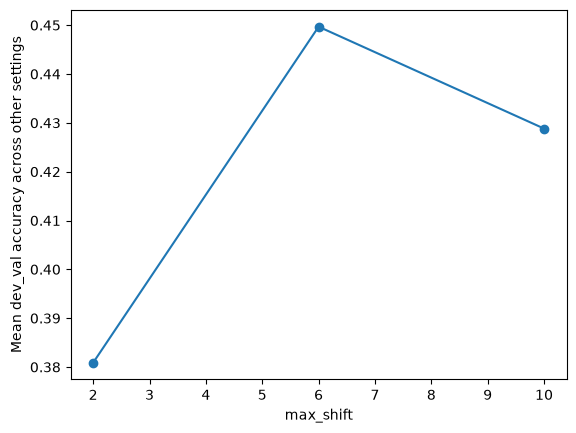

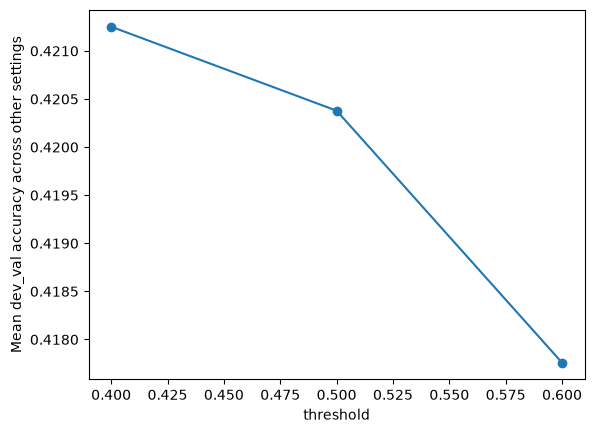

In [5]:
if grid:
    best=max(grid,key=lambda r:float(r['last_accuracy']))
    display(Markdown(f"Cấu hình tốt nhất trên dev_val: pitch={best['pitch']}, shift={best['max_shift']}, threshold={best['threshold']}; accuracy={float(best['last_accuracy']):.3f}. Chưa được suy ra cải thiện trên eval từ bảng này."))
    for key in ('pitch','max_shift','threshold'):
        xs=sorted({float(r[key]) for r in grid})
        ys=[sum(float(r['last_accuracy']) for r in grid if float(r[key])==x)/sum(float(r[key])==x for r in grid) for x in xs]
        plt.plot(xs,ys,marker='o'); plt.xlabel(key); plt.ylabel('Mean dev_val accuracy across other settings'); plt.show()

## E3 - Loại bỏ thành phần (Quang)

Ba phiên bản chạy trên cùng mẫu, tiền xử lý, max_shift và tập đánh giá: baseline (`enabled=False`), bỏ pha giữa hai chữ số (`continuous=False`) và phương pháp đề xuất. Phân tích ở `experiments/quang/README.md`.

In [6]:
e3 = table('e3_summary.csv', QUANG)

[{'method': 'baseline',
  'tier': 'all',
  'n': '2000',
  'd1': '0.964',
  'd2': '0.908',
  'd3': '0.871',
  'd4': '0.8535',
  'd5': '0.4825',
  'first4': '0.899125',
  'full': '0.3715',
  'last_errors': '1035',
  'adjacent_errors': '252',
  'adjacent_fraction': '0.24347826086956523'},
 {'method': 'baseline',
  'tier': 'light',
  'n': '437',
  'd1': '0.9633867276887872',
  'd2': '0.9016018306636155',
  'd3': '0.8489702517162472',
  'd4': '0.8306636155606407',
  'd5': '0.6407322654462243',
  'first4': '0.8861556064073227',
  'full': '0.5148741418764302',
  'last_errors': '157',
  'adjacent_errors': '45',
  'adjacent_fraction': '0.28662420382165604'},
 {'method': 'baseline',
  'tier': 'medium',
  'n': '1156',
  'd1': '0.9662629757785467',
  'd2': '0.907439446366782',
  'd3': '0.8737024221453287',
  'd4': '0.856401384083045',
  'd5': '0.5198961937716263',
  'first4': '0.9009515570934256',
  'full': '0.3944636678200692',
  'last_errors': '555',
  'adjacent_errors': '138',
  'adjacent_fract

## E4 - Điểm gãy (Quang)

Ảnh lăn tổng hợp từ `dev_val`, quét pha φ từ 0 tới 0,5. Đối chiếu với các dự đoán trong `report/challenge-statement.md` ở `experiments/quang/README.md`. Kết quả trên ảnh tổng hợp chỉ cho biết cơ chế, không thay được ảnh lăn thật.

[{'phi': '0.0',
  'n': '165',
  'measured_roll': '0.17853107344632765',
  'proposed_phase_mae': '0.9751306165099267',
  'proposed_phase_median': '0.0862068965517242',
  'proposed_phase_within_quarter': '0.6181818181818182',
  'proposed_reads_lower': '0.6303030303030303',
  'proposed_reads_lower_or_next': '0.6666666666666666',
  'baseline_s2_reads_lower': '0.4484848484848485',
  'baseline_s2_reads_lower_or_next': '0.5272727272727272',
  'baseline_s6_reads_lower': '0.6121212121212121',
  'baseline_s6_reads_lower_or_next': '0.6606060606060606',
  'baseline_s10_reads_lower': '0.6666666666666666',
  'baseline_s10_reads_lower_or_next': '0.7090909090909091'},
 {'phi': '0.05',
  'n': '165',
  'measured_roll': '0.30138674884437594',
  'proposed_phase_mae': '0.8696865203761756',
  'proposed_phase_median': '0.08448275862068932',
  'proposed_phase_within_quarter': '0.6545454545454545',
  'proposed_reads_lower': '0.6727272727272727',
  'proposed_reads_lower_or_next': '0.703030303030303',
  'baselin

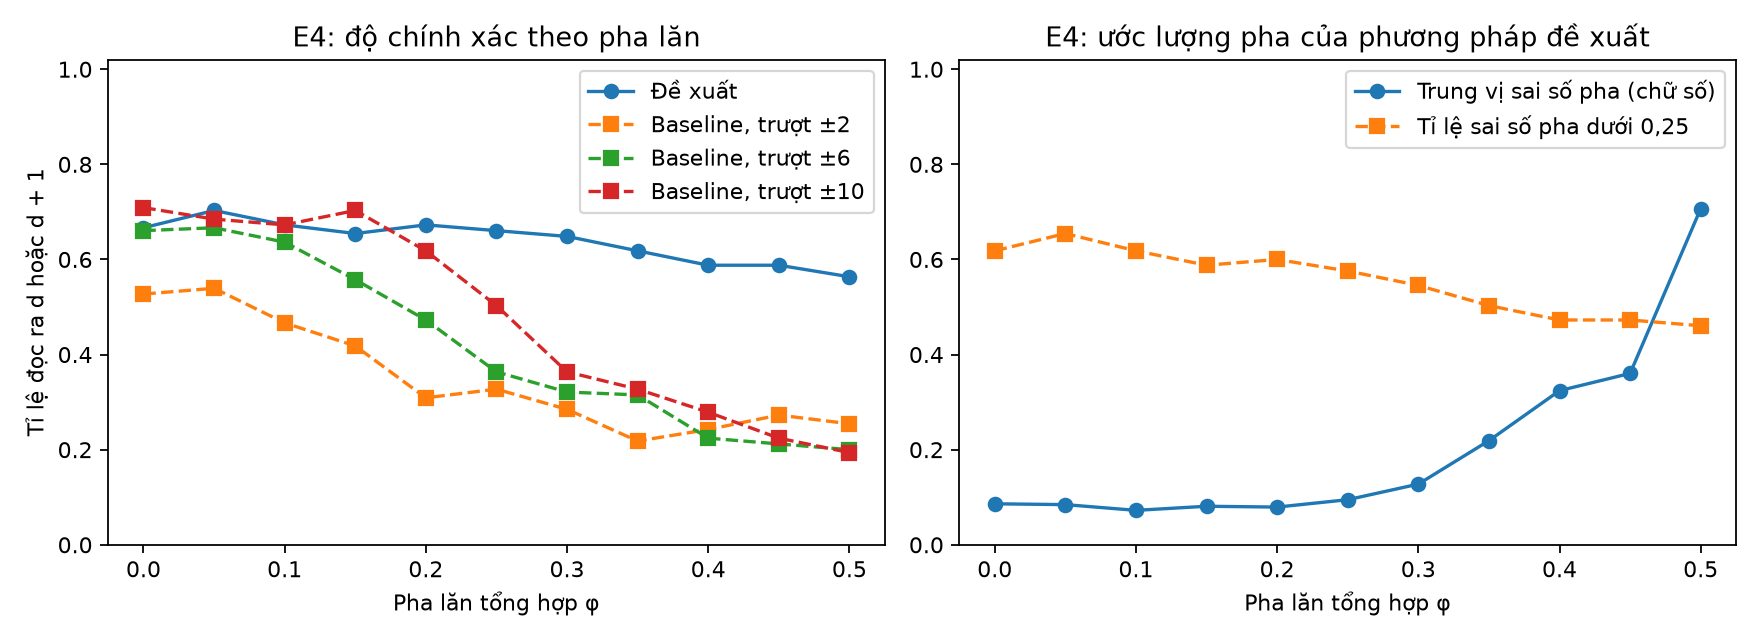

In [7]:
e4 = table('e4_curve.csv', QUANG)
display(Image(filename=str(QUANG / 'e4_curve.png')))

# Kết quả thực nghiệm của Phúc - 15/11/2026

## Dữ liệu và quy trình

Đã giải nén bản Dryad vào `data/Word-Wheel_Water_Meter_Dataset/`, đủ detection và recognition. ZIP SHA-256: `3b7d3d8168ab924314a7c71987ce09f54dec95818a9cb484b46ea804fc1d90e6`, khớp metadata Dryad đã đọc. Ba tập có 9.577/2.290/2.000 ảnh, không thiếu tệp. Đo lại độ lăn trên toàn bộ eval cho nhãn tầng trùng 100% CSV của PR #21: 437 nhẹ, 1.156 trung bình, 407 nặng.

Mẫu chữ số lấy từ 6.178 ảnh dev_fit không half-word. Dò 27 cấu hình trên dev_val, chốt pitch=58, max_shift=6, threshold=0.4 rồi mới đánh giá eval; không chọn lại tham số từ eval. Fingerprint split lưu trong selected.json. Ngưỡng 0.4 là biên dưới của miền khảo sát; dò thêm trên dev_val (pitch 58, shift 6) cho 0.3 là 45,20%, 0.2 là 43,67%, 0.1 là 37,64%, nên 0.4 là cực đại.

## E1 và đánh giá phương pháp

| Phương pháp | Tầng | n | Đúng số cuối (%) | Đúng cả chỉ số (%) | Trung bình bốn số đầu (%) |
|---|---|---:|---:|---:|---:|
| baseline | all | 2000 | 48.25 | 37.15 | 89.91 |
| baseline | light | 437 | 64.07 | 51.49 | 88.62 |
| baseline | medium | 1156 | 51.99 | 39.45 | 90.10 |
| baseline | heavy | 407 | 20.64 | 15.23 | 90.79 |
| proposed | all | 2000 | 54.45 | 42.10 | 89.91 |
| proposed | light | 437 | 64.76 | 51.95 | 88.62 |
| proposed | medium | 1156 | 59.60 | 45.59 | 90.10 |
| proposed | heavy | 407 | 28.75 | 21.62 | 90.79 |

Baseline số cuối giảm từ 64,07% xuống 20,64% giữa tầng nhẹ và nặng (43,43 điểm phần trăm), trong khi bốn số đầu không giảm tương ứng (88,62% và 90,79%). Đây là chứng cứ thách thức tập trung ở ô cuối. Độ sáng trung bình tăng 168,97→173,00; tương phản 38,95→39,98; Laplacian variance 605,83→653,46. Tầng nặng không tối hơn hoặc mờ hơn theo các proxy này. Tuy vậy chưa có kiểm định tương đương và không có ID loại đồng hồ: không tuyên bố đã loại bỏ mọi yếu tố gây nhiễu. Bảng theo chữ số đúng nằm ở e1_by_digit.csv để kiểm tra ảnh hưởng phân bố chữ số.

P cải thiện số cuối 6,20 điểm phần trăm toàn tập, 8,11 điểm ở tầng nặng; cả chuỗi tăng 4,95 điểm. Bốn số đầu giữ nguyên từng dự đoán vì chỉ thay bước nhận dạng ô cuối. Các giá trị là ước lượng điểm, chưa có khoảng tin cậy.

Kết quả cũng không ủng hộ toàn bộ dự đoán trong PR #22: P vẫn giảm từ 64,76% ở tầng nhẹ xuống 28,75% ở tầng nặng. Chỉ 223/911 lỗi số cuối của P lệch một số (24,48%), nên chưa đúng dự đoán phần lớn lỗi là chữ số kề bên. Không sửa dự đoán sau khi xem eval. Mẫu trung bình bị nhòe, kiểu chữ khác nhau, bước bánh xe chung và chiều quay cố định là những khả năng cần kiểm tra ở thí nghiệm phát triển tiếp theo, chưa phải nguyên nhân đã chứng minh.

## E2 - ảnh hưởng tham số

27 cấu hình và accuracy từng tầng trên dev_val ở e2_grid.csv. Cấu hình tốt nhất đạt 45,41% số cuối (nhẹ 59,55%, trung bình 54,23%, nặng 25,89%).

- Giữ pitch=58, threshold=0.4: shift 2/6/10 cho 37,64% / 45,41% / 43,45%. Tăng từ 2 tới 6 giúp bù lệch; tăng lên 10 giảm accuracy, phù hợp khả năng có thêm vị trí khớp nhầm nhưng chưa chứng minh cơ chế này.
- Giữ shift=6, threshold=0.4: pitch 54/58/62 cho 44,98% / 45,41% / 45,11%. Bước 58 tốt nhất toàn tập, còn tầng nặng tốt nhất trong ba cấu hình này là pitch 62 (27,28%); chọn theo tiêu chí toàn dev_val đã định trước.
- Giữ pitch=58, shift=6: threshold 0.4/0.5/0.6 cho 45,41% / 45,20% / 44,98%. Chênh lệch nhỏ, chưa đủ khẳng định mạnh về quy ước nhãn.

Ảnh trung gian raw, cân bằng histogram, ô cuối và cửa sổ dải khớp đặt cạnh nhau trong e2_intermediates.png. Ba ảnh chọn bằng vị trí cố định trong dev_val, không lựa theo kết quả eval.

## Notebook và phần còn lại

Notebook phuc_experiments.ipynb tổng hợp E1/E2 từ CSV thật, có đồ thị và nhận xét. E3/E4 vẫn chờ kết quả của Quang; notebook báo rõ phần chưa có. Vì thế #16 chưa được coi là hoàn tất toàn bộ E1 tới E4. Mã P là bản thực hiện để nhóm review, chưa thay cho việc cả nhóm chốt PR #22. Không đóng issue hay gộp PR tự động.
